# Setup

## Dependencies

In [1]:
import warnings
warnings.simplefilter("ignore", UserWarning)

In [2]:
import sys
sys.path.append('../')

%load_ext autoreload
%autoreload 2

from libs import ios
from libs import vis
from libs.bibs import aps
from libs.inference import categorical
from libs.inference import numeric
from libs import tools_comparison 

Total combinations of features: 1023


In [3]:
# Look & Feel
vis.sns_paper_style()

## Constants

In [ ]:
VERSION = 3
BEST_HZ_REG = 2
BEST_HZ_CLAS = 2
ROOT_DIR = f'../../results/v{VERSION}/'

### OUR DATA
# GT
FN_HZ_REG_GT_METADATA = f"{ROOT_DIR}/gender/predictions_ch/comparison/rs{BEST_HZ_REG}/regression/_mean/ground_truth_MLsampled.csv"
FN_HZ_CLAS_GT_METADATA = f"{ROOT_DIR}/gender/predictions_ch/comparison/rs{BEST_HZ_CLAS}/classification/_mean/cut_1/ground_truth_MLsampled.csv"


# Inferences (HZ: regression, classification; PY: aggregation score and supermajority)
FN_HZ_PY_INF = f'{ROOT_DIR}/gender/predictions_py/uniqueChineseAllGivenNames_PYgender_reg_mean_894_class_mean_607_1.csv'

### OTHER TOOOLS
PINYIN_OTHERS_DIR = f'{ROOT_DIR}/gender/predictions_py_others/'
HANZI_OTHERS_DIR = f'{ROOT_DIR}/gender/predictions_ch_others/'

### HANZI

# Gender score
FN_HZ_SCORE = 'hz_unique_given_names_cnki+_gender_score.csv'
DIR_HZ_SCORE = ios.path_join(HANZI_OTHERS_DIR,'<OTHER_PROVIDER>',FN_HZ_SCORE)
FN_HZ_SCORE_CLAUDE = DIR_HZ_SCORE.replace('<OTHER_PROVIDER>', 'claude')
FN_HZ_SCORE_GPT = DIR_HZ_SCORE.replace('<OTHER_PROVIDER>', 'gpt')
FN_HZ_NAMSOR = DIR_HZ_SCORE.replace('<OTHER_PROVIDER>', 'namsor').replace('_gender_score.', '_gendered.')

# Gender Label
FN_HZ_LABEL = 'hz_unique_given_names_cnki+_gender_label.csv'
DIR_HZ_LABEL = ios.path_join(HANZI_OTHERS_DIR,'<OTHER_PROVIDER>',FN_HZ_LABEL)
FN_HZ_LABEL_CLAUDE = DIR_HZ_LABEL.replace('<OTHER_PROVIDER>', 'claude')
FN_HZ_LABEL_GPT = DIR_HZ_LABEL.replace('<OTHER_PROVIDER>', 'gpt')

### PINYIN

# Gender score
FN_PY_SCORE = 'py_unique_given_names_cnki+_gender_score.csv'
DIR_PY_SCORE = ios.path_join(PINYIN_OTHERS_DIR,'<OTHER_PROVIDER>',FN_PY_SCORE)
FN_PY_SCORE_CLAUDE = DIR_PY_SCORE.replace('<OTHER_PROVIDER>', 'claude')
FN_PY_SCORE_GPT = DIR_PY_SCORE.replace('<OTHER_PROVIDER>', 'gpt')
FN_PY_NAMSOR = DIR_PY_SCORE.replace('<OTHER_PROVIDER>', 'namsor').replace('_gender_score.', '_gendered.')

# Gender Label
FN_PY_LABEL = 'py_unique_given_names_cnki+_gender_label.csv'
DIR_PY_LABEL = ios.path_join(PINYIN_OTHERS_DIR,'<OTHER_PROVIDER>',FN_PY_LABEL)
FN_PY_LABEL_CLAUDE = DIR_PY_LABEL.replace('<OTHER_PROVIDER>', 'claude')
FN_PY_LABEL_GPT = DIR_PY_LABEL.replace('<OTHER_PROVIDER>', 'gpt')

# APS (pinyin_classification)
FN_APS = '../../data/aps-2022_25-10-01_e59319256d553035c40188457bb16edbfe02da04.zip'

### PLOTS
PLOT_OTHERS_DIR = f'{ROOT_DIR}/gender/predictions_<SCRIPT>_others/plots'
PLOT_OTHERS_PY_DIR = PLOT_OTHERS_DIR.replace('<SCRIPT>', 'py')
PLOT_OTHERS_HZ_DIR = PLOT_OTHERS_DIR.replace('<SCRIPT>', 'ch')
PLOT_OTHERS_COMBINED_DIR = PLOT_OTHERS_DIR.replace('<SCRIPT>_', '')

ios.validate_path(PLOT_OTHERS_PY_DIR)
ios.validate_path(PLOT_OTHERS_HZ_DIR)
ios.validate_path(PLOT_OTHERS_COMBINED_DIR)

In [5]:
##############################################################
################ METHODS TO COMPARE WITH GT  #################
##############################################################

METHOD_HZ_SCORE_TITLES = {
        'hz_ngender_mean': "Ground Truth (GT)",
        "hz_ngender_claude": "Claude",
        "hz_ngender_gpt": "GPT",
        "hz_ngender_namsor": "Namsor",
        "hz_ngender": "Ours",
    }

METHOD_PY_GSCORE_TITLE = {k.replace('hz_','py_'):v for k,v in METHOD_HZ_SCORE_TITLES.items()}
METHOD_PY_GSCORE_TITLE['py_weighted_pop'] = f'{METHOD_PY_GSCORE_TITLE["py_ngender"]} (Weighted pop.)'

METHOD_HZ_GLABEL_ORDER = ['hz_gender_claude', 'hz_gender_gpt', 'hz_gender_namsor', 'hz_gender', 'hz_gender_mean']     # hz_gender (regression pred.), hz_gender_mean (GT annotation _smv score)
METHOD_PY_GLABEL_ORDER = ['py_gender_claude', 'py_gender_gpt', 'py_gender_namsor', 'py_gender_smv', 'hz_gender_mean'] # py_gender_smv (supermajority pred.), hz_gender_mean (GT annotation _smv score)

METHOD_HZ_GLABELS_SHORT = {
        "hz_gender_mean": "GT",
        'hz_gender': "Ours",
        "hz_gender_claude": "Clau.",
        "hz_gender_gpt": "GPT",
        "hz_gender_namsor": "Nam.",
    }

METHOD_PY_GLABELS_SHORT = {k.replace('hz_','py_'):v for k,v in METHOD_HZ_GLABELS_SHORT.items()}
METHOD_PY_GLABELS_SHORT['hz_gender_mean'] = METHOD_PY_GLABELS_SHORT['py_gender_mean']
METHOD_PY_GLABELS_SHORT['py_gender_smv'] = METHOD_PY_GLABELS_SHORT["py_gender"]

METHOD_HZ_GLABELS = {
        'hz_gender_mean': "Ground Truth (GT)",
        "hz_gender_claude": "Claude",
        "hz_gender_gpt": "GPT",
        "hz_gender_namsor": "Namsor",
        "hz_gender": "Ours",
    }

METHOD_PY_LABELS = {k.replace('hz_','py_'):v for k,v in METHOD_HZ_GLABELS.items()}
METHOD_PY_LABELS['hz_gender_mean'] = METHOD_PY_LABELS['py_gender_mean']
METHOD_PY_LABELS['py_gender_smv'] = f'{METHOD_PY_LABELS["py_gender"]} (Supermajority)'

##############################################################
################ METHODS TO COMPARE WITH APS #################
##############################################################

APS_METHOD_LABELS = {
        "py_gender_karimi": "Karimi et al. (PY)",
        'py_gender_saeta': 'Saeta (PY)',
        "py_gender_buskirk": "van Buskirk et al. (PY)",

        "py_gender_claude": "Claude (PY)",
        "py_gender_gpt": "GPT (PY)",
        "py_gender_namsor": "Namsor (PY)",
        "py_gender_smv": "Ours (PY)",
        
        "hz_gender": "Ours (HZ)",
        "hz_gender_claude": "Claude (HZ)",
        "hz_gender_gpt": "GPT (HZ)",
        "hz_gender_namsor": "Namsor (HZ)",
    }

APS_METHOD_LABELS_SHORT = {
        "py_gender_karimi":  r"Kar. (PY)",
        'py_gender_saeta':   r"Sae. (PY)",
        "py_gender_buskirk": r"vBu. (PY)",
        
        "py_gender_claude":  r"Clau. (PY)",
        "py_gender_gpt":     r"GPT (PY)",
        "py_gender_namsor":  r"Nam. (PY)",
        "py_gender_smv":     r"Ours (PY)",

        "hz_gender_claude":  r"Clau. (HZ)",
        "hz_gender_gpt":     r"GPT (HZ)",
        "hz_gender_namsor":  r"Nam. (HZ)",
        "hz_gender":         r"Ours (HZ)",
    }

APS_METHOD_HZ_GLABEL_ORDER = ['py_gender_karimi', 'py_gender_saeta',"py_gender_buskirk", 
                              'hz_gender_claude', 'hz_gender_gpt', 'hz_gender_namsor', 
                              'py_gender_smv', 'hz_gender'
                              ]

APS_METHOD_PY_GLABEL_ORDER = ['py_gender_karimi', 'py_gender_saeta',"py_gender_buskirk", 
                              'py_gender_claude', 'py_gender_gpt', 'py_gender_namsor', 
                              'py_gender_smv',    'hz_gender'
                              ]

APS_METHOD_ORDER = ['py_gender_karimi', 
                    'py_gender_saeta',
                    "py_gender_buskirk", 
                    
                    'py_gender_claude', 'hz_gender_claude',
                    'py_gender_gpt',    'hz_gender_gpt', 
                    'py_gender_namsor', 'hz_gender_namsor',
                    
                    'py_gender_smv',    'hz_gender'
                ]

APS_METHOD_COLOR = {
                 # open-source
                 'py_gender_karimi': "#005993", 
                 'py_gender_saeta': "#db5f00",
                 'py_gender_buskirk': "#008004",  
                 # commercial
                 'py_gender_claude': "#b30002",
                 'py_gender_gpt': "#75499b",
                 'py_gender_namsor': "#9b9c00",
                 # commercial
                 'hz_gender_claude': "#db7876",
                 'hz_gender_gpt': "#a48fb3",
                 'hz_gender_namsor': "#b9b96d",
                 # ours
                 'py_gender_smv': "#6B7280", 
                 'hz_gender': "#1F2937"
                 }

hpy = None
hhz = None
APS_METHOD_HATCH = {'py_gender_karimi': None,
                 'py_gender_buskirk': None,
                 'py_gender_saeta': None,

                 'py_gender_claude':hpy,
                 'py_gender_gpt': hpy,
                 'py_gender_namsor': hpy,
                 'py_gender_smv': hpy,

                 'hz_gender_claude':hhz,
                 'hz_gender_gpt': hhz,
                 'hz_gender_namsor': hhz,
                 'hz_gender': None,
                 }

GENDER_LABEL_ORDER = [categorical.UNKNOWN] + categorical.GENDER_LABELS_3

GENDER_MAP = {
    "male": "Male",
    "female": "Female",
    "neutral": "Neutral",
    "unknown": "Unknown",
}

TOOLS_IO_KWARGS = dict(index_col=0, keep_default_na=False, na_values=[""])


## Data

### Ground-truth

In [46]:
# GROUND-TRUTH REGRESSION
df_hz_reg_gt_meta = ios.load_csv(FN_HZ_REG_GT_METADATA)
df_hz_reg_gt_meta.loc[:,'ngender_w'] = df_hz_reg_gt_meta.gender_w.apply(lambda x: 0 if x==categorical.MALE else 1 if x==categorical.FEMALE else numeric.np.nan)

unknown_feature_col = f'{categorical.UNKNOWN}_features'
df_hz_reg_gt_meta.loc[:,unknown_feature_col] = df_hz_reg_gt_meta.apply(lambda row: not ios.pd.notna(row['ngender_r']) and not ios.pd.notna(row['ngender_n']), axis=1)

df_hz_reg_gt_meta = df_hz_reg_gt_meta[['givenname','ngender_w','ngender_n','ngender_r','gender_n','ml_sample',unknown_feature_col,'single_char','ngender_mean']]
df_hz_reg_gt_meta.rename(columns={'givenname':'hz_givenname', 
                                  'ngender_w':'hz_ngender_w', 
                                  'ngender_n':'hz_ngender_n', 
                                  'ngender_r':'hz_ngender_r', 
                                  'gender_n':'hz_gender_n', 
                                  'ml_sample':'ml_sample', 
                                  'ngender_mean':'hz_ngender_mean'}, inplace=True)
df_hz_reg_gt_meta.head(2)

,hz_givenname,hz_ngender_w,hz_ngender_n,hz_ngender_r,hz_gender_n,ml_sample,unknown_features,single_char,hz_ngender_mean
0,东,NaN,0.451906,0.15675,male,train,False,True,0.166667
1,习,NaN,0.460552,0.34495,male,train,False,True,0.312500


In [47]:
# GROUND-TRUTH CLASSIFICATION
df_hz_clas_gt_meta = ios.load_csv(FN_HZ_CLAS_GT_METADATA)
df_hz_clas_gt_meta.loc[:,'ngender_w'] = df_hz_clas_gt_meta.gender_w.apply(lambda x: 0 if x==categorical.MALE else 1 if x==categorical.FEMALE else numeric.np.nan)

unknown_feature_col = f'{categorical.UNKNOWN}_features'
df_hz_clas_gt_meta.loc[:,unknown_feature_col] = df_hz_clas_gt_meta.apply(lambda row: not ios.pd.notna(row['ngender_r']) and not ios.pd.notna(row['ngender_n']), axis=1)

df_hz_clas_gt_meta = df_hz_clas_gt_meta[['givenname', 'ngender_w','ngender_n','ngender_r','gender_n','ml_sample',unknown_feature_col,'single_char','gender_mean']]
df_hz_clas_gt_meta.rename(columns={'givenname':'hz_givenname', 
                                   'ngender_w':'hz_ngender_w', 
                                   'ngender_n':'hz_ngender_n', 
                                   'ngender_r':'hz_ngender_r', 
                                   'gender_n':'hz_gender_n', 
                                   'ml_sample':'ml_sample', 
                                   'gender_mean':'hz_gender_mean'}, inplace=True)
df_hz_clas_gt_meta.head(2)

,hz_givenname,hz_ngender_w,hz_ngender_n,hz_ngender_r,hz_gender_n,ml_sample,unknown_features,single_char,hz_gender_mean
0,东,NaN,0.451906,0.15675,male,train,False,True,male
1,习,NaN,0.460552,0.34495,male,train,False,True,male


### Names

In [48]:
# OUR INFERENCE (PINYIN)
df_hz_py = ios.load_csv(FN_HZ_PY_INF)
df_hz_py = df_hz_py[['givenname','english_one','pred','pred_label','gender_avg_CNKI','gender_avg_all','gender_weighted_pop_CNKI','gender_weighted_pop_NU','male_label_count','female_label_count','neutral_label_count']]
df_hz_py.rename(columns={'givenname':'hz_givenname', 
                         'english_one':'py_givenname', 
                         'pred':'hz_ngender', 
                         'pred_label':'hz_gender',
                         'gender_avg_CNKI':'py_mean_cnki', 'gender_avg_all':'py_mean_cnki+', 'gender_weighted_pop_CNKI':'py_weighted_cnki', 'gender_weighted_pop_NU':'py_weighted_pop'}, inplace=True)
df_hz_py.loc[:, 'py_gender_smv'] = df_hz_py.apply(lambda row: categorical.infer_gender_by_supermajority(row['male_label_count'], row['female_label_count'], row['neutral_label_count']), axis=1)
df_hz_py.head(2)

,hz_givenname,py_givenname,hz_ngender,hz_gender,py_mean_cnki,py_mean_cnki+,py_weighted_cnki,py_weighted_pop,male_label_count,female_label_count,neutral_label_count,py_gender_smv
0,㑇,zhou,0.347726,male,0.280243,0.333601,0.281119,0.279068,28,0,0,male
1,㑊,yi,0.347726,male,0.418201,0.386769,0.379713,0.429543,81,4,48,neutral


In [49]:
df_hz_py.shape
# (46144, 12)

(46144, 12)

In [50]:
df_hz_reg_gt_meta = df_hz_reg_gt_meta.set_index('hz_givenname').join(df_hz_py.set_index('hz_givenname')['py_givenname'], how='inner', rsuffix='_py').reset_index()
df_hz_reg_gt_meta.head(2)

,hz_givenname,hz_ngender_w,hz_ngender_n,hz_ngender_r,hz_gender_n,ml_sample,unknown_features,single_char,hz_ngender_mean,py_givenname
0,东,NaN,0.451906,0.15675,male,train,False,True,0.166667,dong
1,习,NaN,0.460552,0.34495,male,train,False,True,0.312500,xi


In [51]:
df_hz_clas_gt_meta = df_hz_clas_gt_meta.set_index('hz_givenname').join(df_hz_py.set_index('hz_givenname')['py_givenname'], how='inner', rsuffix='_py').reset_index()
df_hz_clas_gt_meta.head(2)

,hz_givenname,hz_ngender_w,hz_ngender_n,hz_ngender_r,hz_gender_n,ml_sample,unknown_features,single_char,hz_gender_mean,py_givenname
0,东,NaN,0.451906,0.15675,male,train,False,True,male,dong
1,习,NaN,0.460552,0.34495,male,train,False,True,male,xi


In [52]:
py_unique_givennames = df_hz_py[['py_givenname']].drop_duplicates().reset_index(drop=True)
hz_unique_givennames = df_hz_py[['hz_givenname']].drop_duplicates().reset_index(drop=True)

for script, df in zip(['py', 'hz'], [py_unique_givennames, hz_unique_givennames]):
    df = df.copy()
    df.loc[:, 'country_code'] = 'CN'
    fn = ios.path_join(PINYIN_OTHERS_DIR if script=='py' else HANZI_OTHERS_DIR, f'{script}_unique_given_names_cnki+.csv')
    if not ios.path_exists(fn):
        # ios.to_csv(df, fn)
        print(f'Saved {df.shape[0]} unique {script} given names to {fn}')
    else:
        print(f'{fn} already exists')

../../results/v3//gender/predictions_py_others/py_unique_given_names_cnki+.csv already exists
../../results/v3//gender/predictions_ch_others/hz_unique_given_names_cnki+.csv already exists


### Tools

In [53]:
# Hanzi - score
df_hz_score_claude = ios.load_csv(FN_HZ_SCORE_CLAUDE, **TOOLS_IO_KWARGS).rename(columns={'hz_ngender':'hz_ngender_claude'})
df_hz_score_gpt = ios.load_csv(FN_HZ_SCORE_GPT, **TOOLS_IO_KWARGS).rename(columns={'hz_ngender':'hz_ngender_gpt'})
df_hz_namsor = ios.load_csv(FN_HZ_NAMSOR, **TOOLS_IO_KWARGS).rename(columns={'likelyGender':'hz_gender_namsor'}).drop(columns=['country_code'])
df_hz_namsor.loc[:,'hz_ngender_namsor'] = df_hz_namsor.genderScale.apply(lambda v: tools_comparison.scale_minus1_to_1_to_0_to_1(v))

df_hz_score_claude.shape, df_hz_score_gpt.shape, df_hz_namsor.shape
# ((46144, 3), (46144, 3), (46144, 10))

((46144, 3), (46144, 3), (46144, 10))

In [54]:
# Hanzi - label
df_hz_label_claude = ios.load_csv(FN_HZ_LABEL_CLAUDE, **TOOLS_IO_KWARGS).rename(columns={'hz_gender':'hz_gender_claude'})
df_hz_label_gpt = ios.load_csv(FN_HZ_LABEL_GPT, **TOOLS_IO_KWARGS).rename(columns={'hz_gender':'hz_gender_gpt'})

df_hz_label_claude.shape, df_hz_label_gpt.shape, df_hz_namsor.shape
# ((46144, 3), (46144, 3), (46144, 10))

((46144, 3), (46144, 3), (46144, 10))

In [55]:
# Pinyin - score
df_py_score_claude = ios.load_csv(FN_PY_SCORE_CLAUDE, **TOOLS_IO_KWARGS).rename(columns={'py_ngender':'py_ngender_claude'})
df_py_score_gpt = ios.load_csv(FN_PY_SCORE_GPT, **TOOLS_IO_KWARGS).rename(columns={'py_ngender':'py_ngender_gpt'})
df_py_namsor = ios.load_csv(FN_PY_NAMSOR, **TOOLS_IO_KWARGS).rename(columns={'likelyGender':'py_gender_namsor'}).drop(columns=['country_code'])
df_py_namsor.loc[:,'py_ngender_namsor'] = df_py_namsor.genderScale.apply(lambda v: tools_comparison.scale_minus1_to_1_to_0_to_1(v))

df_py_score_claude.shape, df_py_score_gpt.shape, df_py_namsor.shape
# ((18740, 3), (18740, 3), (18740, 10))

((18740, 3), (18740, 3), (18740, 10))

In [56]:
# Pinyin - label
df_py_label_claude = ios.load_csv(FN_PY_LABEL_CLAUDE, **TOOLS_IO_KWARGS).rename(columns={'py_gender':'py_gender_claude'}).rename(columns={'py_gender':'py_gender_claude'})
df_py_label_gpt = ios.load_csv(FN_PY_LABEL_GPT, **TOOLS_IO_KWARGS).rename(columns={'py_gender':'py_gender_gpt'})

df_py_label_claude.shape, df_py_label_gpt.shape, df_py_namsor.shape
# ((18740, 3), (18740, 3), (18740, 10))


((18740, 3), (18740, 3), (18740, 10))

<!-- # Evaluation (against GT) -->

## Gender score

In [57]:
df_hz_gt_baselines_score = df_hz_reg_gt_meta.set_index('hz_givenname').join(df_hz_py.set_index('hz_givenname'), how='inner', rsuffix='_py').join(df_hz_score_claude.set_index('hz_givenname'), how='inner', rsuffix='_claude').join(df_hz_score_gpt.set_index('hz_givenname'), how='inner', rsuffix='_gpt').join(df_hz_namsor.set_index('hz_givenname'), how='inner', rsuffix='_namsor').reset_index()
df_hz_gt_baselines_score

,hz_givenname,hz_ngender_w,hz_ngender_n,hz_ngender_r,hz_gender_n,ml_sample,unknown_features,single_char,hz_ngender_mean,py_givenname,...,uncertainty_gpt,apiVersion,script,firstName,lastName,hz_gender_namsor,genderScale,score,probabilityCalibrated,hz_ngender_namsor
0,东,NaN,0.451906,0.15675,male,train,False,True,0.166667,dong,...,0.22,namsor_api_2.1.4,HAN,东,NaN,male,-0.811201,6.233968,0.905601,0.094399
1,习,NaN,0.460552,0.34495,male,train,False,True,0.312500,xi,...,0.44,namsor_api_2.1.4,HAN,习,NaN,female,0.440516,2.859879,0.720258,0.720258
2,仅,NaN,0.545362,0.60040,female,test,False,True,0.458333,jin,...,0.97,namsor_api_2.1.4,HAN,仅,NaN,male,-0.090187,0.625961,0.545094,0.454906
3,县,NaN,0.552551,0.13905,female,train,False,True,0.354167,xian,...,0.97,namsor_api_2.1.4,HAN,县,NaN,female,0.093737,0.647005,0.546869,0.546869
4,园,NaN,0.535775,0.78480,female,train,False,True,0.625000,yuan,...,0.42,namsor_api_2.1.4,HAN,园,NaN,female,0.970046,10.318584,0.985023,0.985023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161,静平,0.0,0.538443,0.66210,female,train,False,False,0.479167,jingping,...,0.80,namsor_api_2.1.4,HAN,静平,NaN,female,0.986893,12.881084,0.993446,0.993446
162,颖伶,1.0,0.647493,0.90300,female,train,False,False,0.833333,yingling,...,0.22,namsor_api_2.1.4,HAN,颖伶,NaN,female,0.850488,6.820906,0.925244,0.925244
163,颖弢,0.0,0.389434,0.50435,male,train,False,False,0.625000,yingtao,...,0.70,namsor_api_2.1.4,HAN,颖弢,NaN,female,0.278868,1.636620,0.639434,0.639434
164,馨心,1.0,0.551107,0.76760,female,train,False,False,0.895833,xinxin,...,0.35,namsor_api_2.1.4,HAN,馨心,NaN,female,0.998351,15.303116,0.999176,0.999176


In [59]:
df_hz_gt_baselines_score[['hz_ngender_n','hz_ngender_namsor']].describe()

,hz_ngender_n,hz_ngender_namsor
count,156.000000,166.000000
mean,0.470961,0.602881
std,0.098678,0.289681
min,0.262382,0.000025
25%,0.410359,0.422104
50%,0.461227,0.605649
75%,0.544777,0.844461
max,0.705781,1.000000


N: 156
R² Score: -7.2382
RMSE:     0.2823
Pearson:  0.6410


<Axes: xlabel='hz_ngender_n', ylabel='hz_ngender_namsor'>

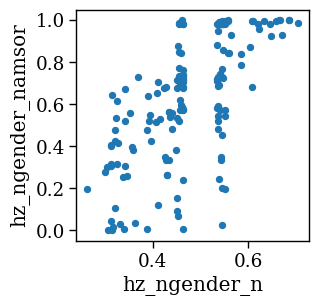

In [60]:
# Differences between namsor score from first query (to construct X features)
# and second query (to make the comparison across tools)
from sklearn.metrics import r2_score, root_mean_squared_error
from scipy.stats import pearsonr

tmp = df_hz_gt_baselines_score.dropna(subset=['hz_ngender_n','hz_ngender_namsor'])
first = tmp.loc[:,'hz_ngender_n']
second = tmp.loc[:,'hz_ngender_namsor']

r2 = r2_score(first, second)
rmse = root_mean_squared_error(first, second)
pearson_corr, _ = pearsonr(first, second)

print(f"N: {tmp.shape[0]}")
print(f"R² Score: {r2:.4f}")
print(f"RMSE:     {rmse:.4f}")
print(f"Pearson:  {pearson_corr:.4f}")

df_hz_gt_baselines_score[['hz_ngender_n','hz_ngender_namsor']].plot.scatter('hz_ngender_n','hz_ngender_namsor',figsize=(3,3))

In [62]:
import pandas as pd
def label_flip_rate(df: pd.DataFrame, col_a: str, col_b: str) -> dict:
    """Share of names whose label differs between two columns.

    Rows where either label is missing are excluded and counted separately.
    """
    pair = df[[col_a, col_b]]
    complete = pair.dropna()

    flipped = complete[col_a] != complete[col_b]

    return {
        "n_compared": len(complete),
        "n_missing": len(pair) - len(complete),
        "n_flipped": int(flipped.sum()),
        "flip_rate": flipped.mean(),
        "crosstab": pd.crosstab(complete[col_a], complete[col_b],
                                rownames=["call 1"], colnames=["call 2"]),
    }


# usage
col_a, col_b = 'hz_gender_n','hz_gender_namsor'
res = label_flip_rate(df_hz_gt_baselines_score, col_a, col_b)
print(f"{res['n_flipped']}/{res['n_compared']} labels flipped "
      f"({res['flip_rate']:.1%}); {res['n_missing']} names missing")
print(res["crosstab"])

73/166 labels flipped (44.0%); 0 names missing
call 2   female  male
call 1               
female       53     8
male         55    40
unknown       0    10


In [63]:
df_hz_gt_baselines_score[['py_givenname','hz_givenname',col_a,col_b,'hz_ngender_n','hz_ngender_namsor']]

,py_givenname,hz_givenname,hz_gender_n,hz_gender_namsor,hz_ngender_n,hz_ngender_namsor
0,dong,东,male,male,0.451906,0.094399
1,xi,习,male,female,0.460552,0.720258
2,jin,仅,female,male,0.545362,0.454906
3,xian,县,female,female,0.552551,0.546869
4,yuan,园,female,female,0.535775,0.985023
...,...,...,...,...,...,...
161,jingping,静平,female,female,0.538443,0.993446
162,yingling,颖伶,female,female,0.647493,0.925244
163,yingtao,颖弢,male,female,0.389434,0.639434
164,xinxin,馨心,female,female,0.551107,0.999176


In [21]:
df_py_gt_baselines_score = df_hz_reg_gt_meta.set_index('py_givenname').join(df_hz_py.drop_duplicates(subset='py_givenname', keep='first').set_index('py_givenname'), how='inner', rsuffix='_py').join(df_py_score_claude.set_index('py_givenname'), how='inner', rsuffix='_claude').join(df_py_score_gpt.set_index('py_givenname'), how='inner', rsuffix='_gpt').join(df_py_namsor.set_index('py_givenname'), how='inner', rsuffix='_namsor').reset_index()
df_py_gt_baselines_score


,py_givenname,hz_givenname,hz_ngender_w,hz_ngender_n,hz_ngender_r,ml_sample,unknown_features,single_char,hz_ngender_mean,hz_givenname_py,...,uncertainty_gpt,apiVersion,script,firstName,lastName,py_gender_namsor,genderScale,score,probabilityCalibrated,py_ngender_namsor
0,dong,东,NaN,0.451906,0.15675,train,False,True,0.166667,东,...,0.45,namsor_api_2.1.4,LATIN,dong,NaN,male,-0.972433,11.122401,0.986217,0.013783
1,xi,习,NaN,0.460552,0.34495,train,False,True,0.312500,习,...,0.75,namsor_api_2.1.4,LATIN,xi,NaN,female,0.311861,1.809251,0.655930,0.655930
2,jin,仅,NaN,0.545362,0.60040,test,False,True,0.458333,仅,...,0.75,namsor_api_2.1.4,LATIN,jin,NaN,male,-0.570394,4.263732,0.785197,0.214803
3,xian,县,NaN,0.552551,0.13905,train,False,True,0.354167,㬎,...,0.76,namsor_api_2.1.4,LATIN,xian,NaN,female,0.042446,0.330899,0.521223,0.521223
4,yuan,园,NaN,0.535775,0.78480,train,False,True,0.625000,元,...,0.64,namsor_api_2.1.4,LATIN,yuan,NaN,male,-0.179599,1.209943,0.589799,0.410201
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161,jingping,静平,0.0,0.538443,0.66210,train,False,False,0.479167,京平,...,0.62,namsor_api_2.1.4,LATIN,jingping,NaN,female,0.911020,7.666157,0.955510,0.955510
162,yingling,颖伶,1.0,0.647493,0.90300,train,False,False,0.833333,应岭,...,0.55,namsor_api_2.1.4,LATIN,yingling,NaN,female,0.972155,10.987780,0.986077,0.986077
163,yingtao,颖弢,0.0,0.389434,0.50435,train,False,False,0.625000,应涛,...,0.50,namsor_api_2.1.4,LATIN,yingtao,NaN,male,-0.966724,9.630212,0.983362,0.016638
164,xinxin,馨心,1.0,0.551107,0.76760,train,False,False,0.895833,信信,...,0.50,namsor_api_2.1.4,LATIN,xinxin,NaN,female,0.783509,5.906960,0.891755,0.891755


../../results/v3//gender/predictions_ch_others/plots/comparison_hz_gt_vs_methods.pdf
Plotting hz_ngender vs. hz_ngender_mean...
Plotting hz_ngender_namsor vs. hz_ngender_mean...
Plotting hz_ngender_claude vs. hz_ngender_mean...
Plotting hz_ngender_gpt vs. hz_ngender_mean...


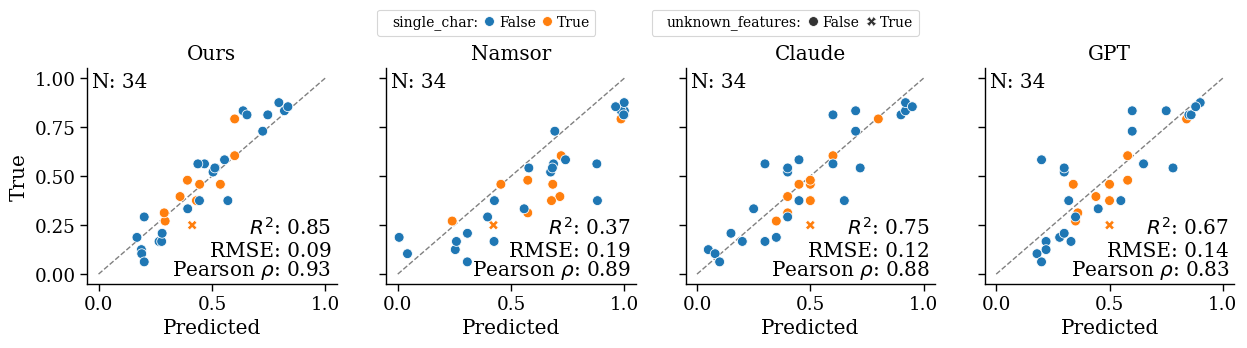

../../results/v3//gender/predictions_py_others/plots/comparison_py_gt_vs_methods.pdf
Plotting py_weighted_pop vs. hz_ngender_mean...
Plotting py_ngender_namsor vs. hz_ngender_mean...
Plotting py_ngender_claude vs. hz_ngender_mean...
Plotting py_ngender_gpt vs. hz_ngender_mean...
[Warning] Dropped 1 rows with NaN values


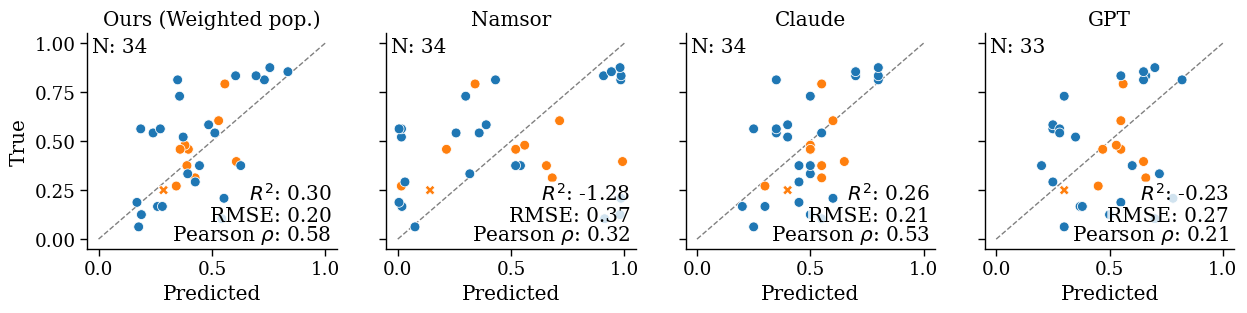

In [22]:
methods = {'hz':['hz_ngender',      'hz_ngender_namsor','hz_ngender_claude','hz_ngender_gpt'], # predictions ML
           'py':['py_weighted_pop', 'py_ngender_namsor','py_ngender_claude','py_ngender_gpt']  # aggregations
           }

col_true = 'hz_ngender_mean' # GT annotation mean score
ml_sample = 'test'
width = 3.7
height = 2.8

for script, df, titles in zip(['hz', 'py'], [df_hz_gt_baselines_score, df_py_gt_baselines_score], [METHOD_HZ_SCORE_TITLES, METHOD_PY_GSCORE_TITLE]):

    ncols = len(methods[script])
    fig, axes = vis.plt.subplots(1, ncols, figsize=(width*ncols, height), sharex=True, sharey=True)

    path = PLOT_OTHERS_DIR.replace('<SCRIPT>', 'ch' if script=='hz' else script)
    fn = ios.path_join(path, f"comparison_{script}_gt_vs_methods.pdf")
    print(fn)

    cols = [c for c in df.columns if c.startswith(script)]
    for col_id, col_pred in enumerate(methods[script]):

        ax = axes[col_id]
        
        print(f"Plotting {col_pred} vs. {col_true}...")
        
        vis.plot_scatter(df.query("ml_sample==@ml_sample"), 
                        
                        x=col_pred,  
                        xlabel="Predicted",

                        y=col_true, 
                        ylabel='True' if col_id==0 else None, 
                        
                        true_var = col_true,

                        markersize=50,
                        title=titles.get(col_pred, ''),  
                        hue='single_char', 
                        hue_order=[False, True], 
                        
                        style = unknown_feature_col,
                        style_order = [False, True],
                        
                        flatten_legend=True, 
                        
                        palette=None, 
                        corr=True, fit=False, rmse=True, r2=True, diagonal=True,
                        fn=fn,
                        
                        show_legend = col_id == 1 and script=='hz', # Only show legend for the second plot of Hanzi (since it has more methods)
                        legend_kwargs={'bbox_to_anchor': (0.4, 1.12), 'fontsize': 10, 'title_fontsize':12},

                        ax = ax,
                        save_and_close=col_id==len(methods[script])-1
                        )

## Gender Labels

In [23]:
df_hz_gt_baselines_label = df_hz_clas_gt_meta.set_index('hz_givenname').join(df_hz_py.set_index('hz_givenname'), how='inner', rsuffix='_py').join(df_hz_label_claude.set_index('hz_givenname'), how='inner', rsuffix='_claude').join(df_hz_label_gpt.set_index('hz_givenname'), how='inner', rsuffix='_gpt').join(df_hz_namsor.set_index('hz_givenname'), how='inner', rsuffix='_namsor').reset_index()
df_hz_gt_baselines_label

,hz_givenname,hz_ngender_w,hz_ngender_n,hz_ngender_r,ml_sample,unknown_features,single_char,hz_gender_mean,py_givenname,py_givenname_py,...,uncertainty_gpt,apiVersion,script,firstName,lastName,hz_gender_namsor,genderScale,score,probabilityCalibrated,hz_ngender_namsor
0,东,NaN,0.451906,0.15675,train,False,True,male,dong,dong,...,0.55,namsor_api_2.1.4,HAN,东,NaN,male,-0.811201,6.233968,0.905601,0.094399
1,习,NaN,0.460552,0.34495,train,False,True,male,xi,xi,...,0.95,namsor_api_2.1.4,HAN,习,NaN,female,0.440516,2.859879,0.720258,0.720258
2,仅,NaN,0.545362,0.60040,test,False,True,neutral,jin,jin,...,0.98,namsor_api_2.1.4,HAN,仅,NaN,male,-0.090187,0.625961,0.545094,0.454906
3,县,NaN,0.552551,0.13905,train,False,True,neutral,xian,xian,...,0.98,namsor_api_2.1.4,HAN,县,NaN,female,0.093737,0.647005,0.546869,0.546869
4,园,NaN,0.535775,0.78480,train,False,True,neutral,yuan,yuan,...,0.50,namsor_api_2.1.4,HAN,园,NaN,female,0.970046,10.318584,0.985023,0.985023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161,静平,0.0,0.538443,0.66210,train,False,False,neutral,jingping,jingping,...,0.50,namsor_api_2.1.4,HAN,静平,NaN,female,0.986893,12.881084,0.993446,0.993446
162,颖伶,1.0,0.647493,0.90300,train,False,False,female,yingling,yingling,...,0.30,namsor_api_2.1.4,HAN,颖伶,NaN,female,0.850488,6.820906,0.925244,0.925244
163,颖弢,0.0,0.389434,0.50435,train,False,False,neutral,yingtao,yingtao,...,0.70,namsor_api_2.1.4,HAN,颖弢,NaN,female,0.278868,1.636620,0.639434,0.639434
164,馨心,1.0,0.551107,0.76760,train,False,False,female,xinxin,xinxin,...,0.28,namsor_api_2.1.4,HAN,馨心,NaN,female,0.998351,15.303116,0.999176,0.999176


In [24]:
df_py_gt_baselines_label = df_hz_clas_gt_meta.set_index('py_givenname').join(df_hz_py.drop_duplicates(subset='py_givenname', keep='first').set_index('py_givenname'), how='inner', rsuffix='_py').join(df_py_label_claude.set_index('py_givenname'), how='inner', rsuffix='_claude').join(df_py_label_gpt.set_index('py_givenname'), how='inner', rsuffix='_gpt').join(df_py_namsor.set_index('py_givenname'), how='inner', rsuffix='_namsor').reset_index()
df_py_gt_baselines_label

,py_givenname,hz_givenname,hz_ngender_w,hz_ngender_n,hz_ngender_r,ml_sample,unknown_features,single_char,hz_gender_mean,hz_givenname_py,...,uncertainty_gpt,apiVersion,script,firstName,lastName,py_gender_namsor,genderScale,score,probabilityCalibrated,py_ngender_namsor
0,dong,东,NaN,0.451906,0.15675,train,False,True,male,东,...,0.40,namsor_api_2.1.4,LATIN,dong,NaN,male,-0.972433,11.122401,0.986217,0.013783
1,xi,习,NaN,0.460552,0.34495,train,False,True,male,习,...,1.00,namsor_api_2.1.4,LATIN,xi,NaN,female,0.311861,1.809251,0.655930,0.655930
2,jin,仅,NaN,0.545362,0.60040,test,False,True,neutral,仅,...,1.00,namsor_api_2.1.4,LATIN,jin,NaN,male,-0.570394,4.263732,0.785197,0.214803
3,xian,县,NaN,0.552551,0.13905,train,False,True,neutral,㬎,...,0.50,namsor_api_2.1.4,LATIN,xian,NaN,female,0.042446,0.330899,0.521223,0.521223
4,yuan,园,NaN,0.535775,0.78480,train,False,True,neutral,元,...,0.55,namsor_api_2.1.4,LATIN,yuan,NaN,male,-0.179599,1.209943,0.589799,0.410201
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161,jingping,静平,0.0,0.538443,0.66210,train,False,False,neutral,京平,...,0.50,namsor_api_2.1.4,LATIN,jingping,NaN,female,0.911020,7.666157,0.955510,0.955510
162,yingling,颖伶,1.0,0.647493,0.90300,train,False,False,female,应岭,...,0.35,namsor_api_2.1.4,LATIN,yingling,NaN,female,0.972155,10.987780,0.986077,0.986077
163,yingtao,颖弢,0.0,0.389434,0.50435,train,False,False,neutral,应涛,...,0.35,namsor_api_2.1.4,LATIN,yingtao,NaN,male,-0.966724,9.630212,0.983362,0.016638
164,xinxin,馨心,1.0,0.551107,0.76760,train,False,False,female,信信,...,0.50,namsor_api_2.1.4,LATIN,xinxin,NaN,female,0.783509,5.906960,0.891755,0.891755


(32, 33)
Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:

Cohen's Kappa matrix (chance-corrected agreement):
../../results/v3//gender/predictions_ch_others/plots/hz_gender_pairwise_agreement.pdf


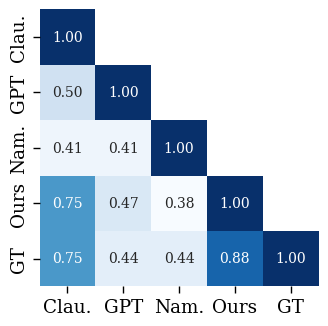

../../results/v3//gender/predictions_ch_others/plots/hz_gender_pairwise_kappa.pdf


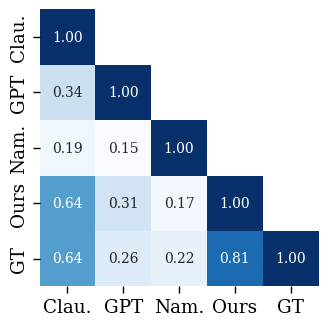

(32, 33)
Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:

Cohen's Kappa matrix (chance-corrected agreement):
../../results/v3//gender/predictions_py_others/plots/py_gender_pairwise_agreement.pdf


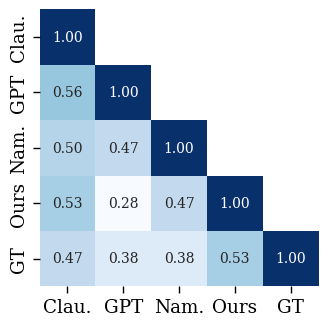

../../results/v3//gender/predictions_py_others/plots/py_gender_pairwise_kappa.pdf


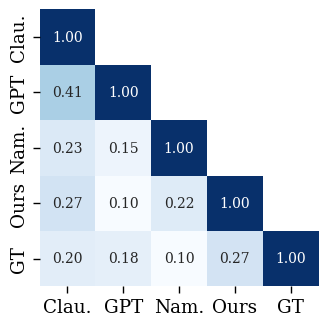

In [25]:

for script, df, order, label_short, path in zip(['hz', 'py'], [df_hz_gt_baselines_label, df_py_gt_baselines_label], 
                                          [METHOD_HZ_GLABEL_ORDER, METHOD_PY_GLABEL_ORDER], 
                                          [METHOD_HZ_GLABELS_SHORT, METHOD_PY_GLABELS_SHORT], 
                                          [PLOT_OTHERS_HZ_DIR, PLOT_OTHERS_PY_DIR]):

    df = df.query("ml_sample=='test'")
    print(df.shape)
    
    # 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
    agreement_gt_ch = categorical.pairwise_agreement(df, order)
    print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
    # display(agreement_gt_ch.round(2))

    # 2) Cohen's Kappa — agreement corrected for chance
    kappa_gt_ch = categorical.pairwise_kappa(df, order)
    print("\nCohen's Kappa matrix (chance-corrected agreement):")
    # display(kappa_gt_ch.round(2))

    for kind, arr in {'agreement':agreement_gt_ch,'kappa':kappa_gt_ch}.items():
        arr = arr.to_numpy()
        arr[categorical.np.triu_indices(arr.shape[0], k=1)] = categorical.np.nan

        fn = ios.path_join(path, f'{script}_gender_pairwise_{kind}.pdf')
        print(fn)

        vis.plot_confusion_matrix(arr, [label_short[m] for m in order], 
                                title=None,
                                xlabel=None,
                                ylabel=None,
                                cbar=False,
                                annot_kws={'fontsize': 10},
                                cmap='Blues', figsize=(3.6, 3.6),
                                fn=fn,
                                )
        

============= hz =============
(32, 33)
['hz_gender_claude', 'hz_gender_gpt', 'hz_gender_namsor', 'hz_gender', 'hz_gender_mean']
../../results/v3//gender/predictions_ch_others/plots/hz_gender_cm_recall.pdf
../../results/v3//gender/predictions_ch_others/plots/hz_gender_cm_precision.pdf
../../results/v3//gender/predictions_ch_others/plots/hz_gender_cm_counts.pdf
============= py =============
(32, 33)
['py_gender_claude', 'py_gender_gpt', 'py_gender_namsor', 'py_gender_smv', 'hz_gender_mean']
../../results/v3//gender/predictions_py_others/plots/py_gender_cm_recall.pdf
../../results/v3//gender/predictions_py_others/plots/py_gender_cm_precision.pdf
../../results/v3//gender/predictions_py_others/plots/py_gender_cm_counts.pdf


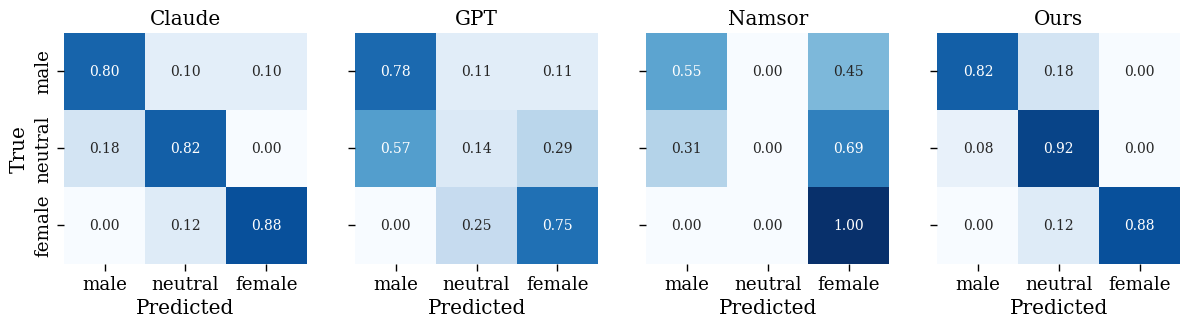

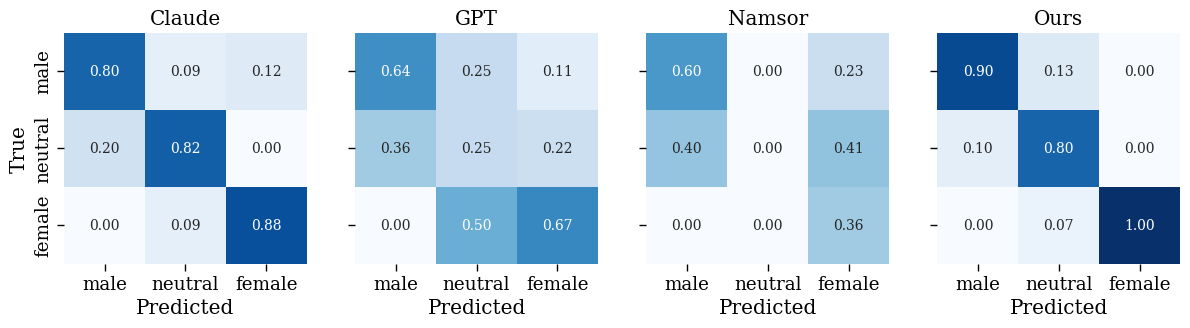

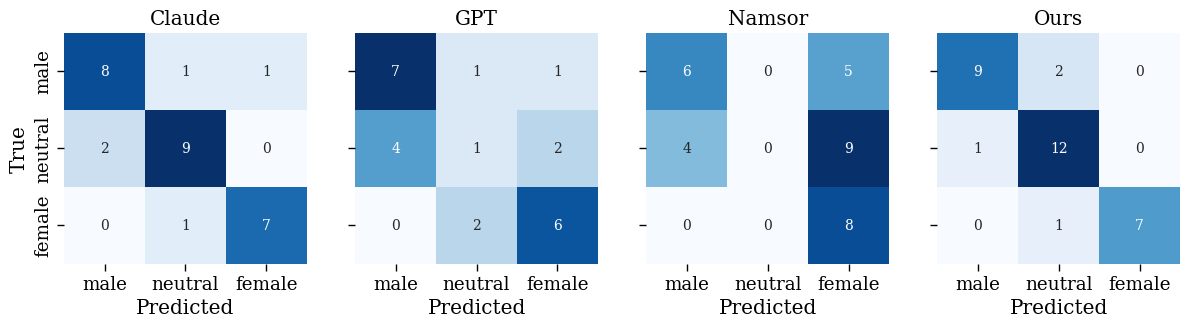

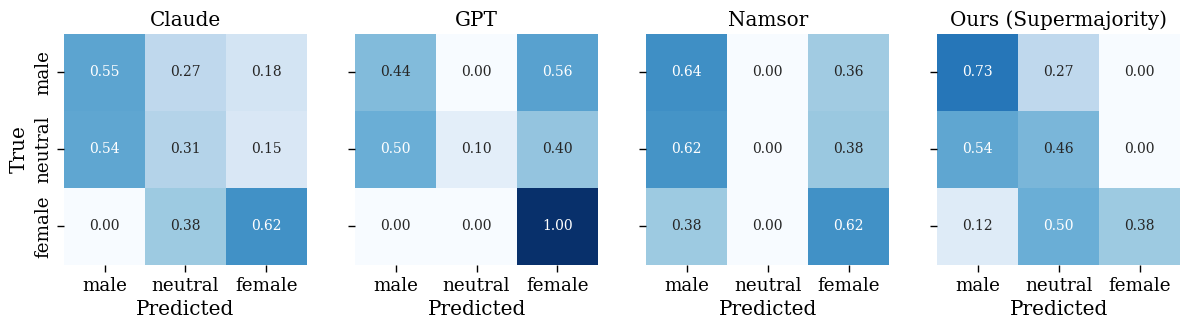

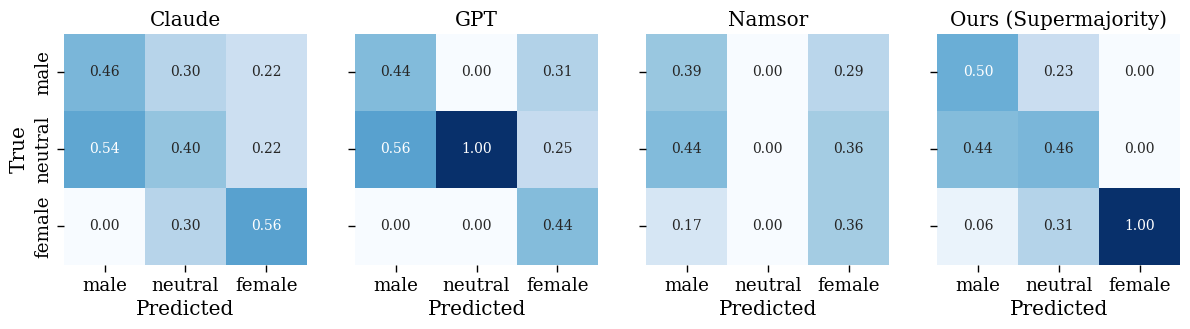

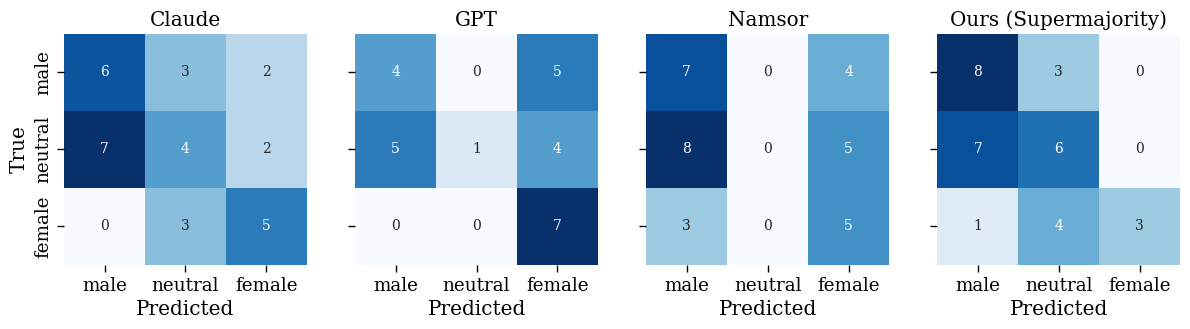

In [26]:
col_ref = 'hz_gender_mean'
labels = categorical.GENDER_LABELS_3

for script, df, order, title, path in zip(['hz', 'py'], [df_hz_gt_baselines_label, df_py_gt_baselines_label], 
                                    [METHOD_HZ_GLABEL_ORDER, METHOD_PY_GLABEL_ORDER], 
                                    [METHOD_HZ_GLABELS, METHOD_PY_LABELS], 
                                    [PLOT_OTHERS_HZ_DIR, PLOT_OTHERS_PY_DIR]):

    print(f"============= {script} =============")
    df = df.query("ml_sample=='test'")
    print(df.shape)
    print(order)

    methods = [c for c in order if c != col_ref]
    nrows = 1
    ncols = len(methods)
    width = 3.6
    height = 3.0

    for norm, metric in {'true':'Recall', 'pred':'Precision', None:'Counts'}.items():
        
        fig, axes = vis.create_plot(nrows=nrows, ncols=ncols, figsize=(width * ncols, height * nrows), sharex=True, sharey=True)
        
        for icol, col in enumerate(methods):
            
            ax = axes[icol]
            vmin, vmax = (0, 1) if norm else (None, None)
            cbar = False
            cm = categorical.confusion_matrix(y_true=df[col_ref], y_pred=df[col], labels=labels, normalize=norm)
            vis.plot_confusion_matrix(cm, labels, None, 
                                    cbar=cbar, 
                                    vmin=vmin, vmax=vmax, 
                                    ax=ax,
                                    finalize=False)
            ax.set_xlabel("Predicted")
            ax.set_title(f"{title[col]}")
            
        axes[0].set_ylabel("True")

        fn = ios.path_join(path, f'{script}_gender_cm_{metric.lower()}.pdf')
        if fn is not None:
            fig.savefig(fn, bbox_inches='tight', dpi=vis.FIG_DPI)
            print(fn)
    


# Evaluation (against APS)

In [27]:
_df_aps_authors = ios.read_csv_from_zip(FN_APS, 'data/authors.csv')
_df_aps_authors_names = ios.read_csv_from_zip(FN_APS, 'data/author_names.csv')
_df_aps_genders = ios.read_csv_from_zip(FN_APS, 'data/genders.csv')

df_aps = ios.pd.merge(_df_aps_authors, _df_aps_authors_names, how='inner', on='id_author', suffixes=("_a","_n"))
df_aps = ios.pd.merge(df_aps, _df_aps_genders, how='left', on='id_gender')
df_aps = df_aps[['id_author','id_author_name','name','gender','gender_nq', 'disambiguated']] # NOTE: it contains disambiguated True and False

print(f"APS authors: {_df_aps_authors.shape}")
print(f"APS authors names: {_df_aps_authors_names.shape}")
print(f"APS genders: {_df_aps_genders.shape}")
print(f"APS all authors merged: {df_aps.shape}")

df_aps_clean = aps.clean_aps_names(df_aps)
df_aps_clean_ch_py = aps.detect_pinyin_and_chinese_names(df_aps_clean)
print(f"APS clean hz-py: {df_aps_clean_ch_py.shape} (has_py_hz: {df_aps_clean_ch_py.has_py_hz.value_counts()})")

# APS authors: (874556, 4)
# APS authors names: (948771, 4)
# APS genders: (3, 2)
# APS all authors merged: (948771, 6)
# APS clean ch-py: (874556, 15) (has_py_hz: has_py_hz
# True     2636
# False    1086
# Name: count, dtype: int64)


APS authors: (874556, 4)
APS authors names: (948771, 4)
APS genders: (3, 2)
APS all authors merged: (948771, 6)
APS clean hz-py: (874556, 15) (has_py_hz: has_py_hz
True     2636
False    1086
Name: count, dtype: int64)


In [28]:
# Given names with "()" whose names contain pinyin and Hanzi
df_aps_hz = df_aps_clean_ch_py.query('has_py_hz == True').copy()
df_aps_hz.rename(columns={'gender_clean': 'py_gender_karimi', 'gender_nq_clean': 'py_gender_buskirk'}, inplace=True)
df_aps_hz.loc[:,'py_gender_buskirk'] = df_aps_hz.loc[:,'py_gender_buskirk'].replace({'gm': 'male', 'gf': 'female'})
df_aps_hz.shape
# (2636, 15)

(2636, 15)

In [29]:
# Check how many reconstructed pinyin names match original pinyin names
# IF they don't match it means the original name is an initial; so unfair comparison with othe rmodels as we use the full reconstructed pinyin.
stats_pinyin_names_reconstructed = df_aps_hz.apply(lambda row: row.py_givenname_original == row.py_givenname and '.' not in row.py_givenname_original, axis=1).value_counts()
print(f"Reconstructed pinyin names match original pinyin names: \n{stats_pinyin_names_reconstructed}")

stats_pinyin_names_reconstructed /= stats_pinyin_names_reconstructed.sum()
print(f"\nReconstructed pinyin names match original pinyin names (proportion): \n{(stats_pinyin_names_reconstructed*100).round(2)}%")

# Keep only rows where reconstructed pinyin names match original pinyin names
_tmp = df_aps_hz[df_aps_hz.apply(lambda row: row.py_givenname_original != row.py_givenname, axis=1)].copy()
_tmp.drop_duplicates(subset=['py_givenname','hz_givenname'], inplace=True) # keep only unique pinyin-chinese given name pairs
print(f"\nRows where reconstructed pinyin names does NOT match original pinyin names (unique PY-CH pairs): {_tmp.shape}")

df_aps_hz_inter = df_aps_hz[df_aps_hz.apply(lambda row: row.py_givenname_original == row.py_givenname, axis=1)].copy()
df_aps_hz_inter.drop_duplicates(subset=['py_givenname','hz_givenname'], inplace=True) # keep only unique pinyin-chinese given name pairs
print(f"After keeping only rows where reconstructed pinyin names match original pinyin names (unique PY-CH pairs): {df_aps_hz_inter.shape}")

print(f"Totals:")
print(f"- Unique PY-CH pairs: {_tmp.shape[0]+df_aps_hz_inter.shape[0]} ({_tmp.hz_givenname.nunique()+df_aps_hz_inter.hz_givenname.nunique()})")
print(f"- Unique PY-CH pairs (original pinyin is an initial): {_tmp.shape[0]} ({(_tmp.shape[0] / (_tmp.shape[0]+df_aps_hz_inter.shape[0]))*100:.2f}%)")
print(f"- Unique PY-CH pairs (original pinyin is correct): {df_aps_hz_inter.shape[0]} ({(df_aps_hz_inter.shape[0] / (_tmp.shape[0]+df_aps_hz_inter.shape[0]))*100:.2f}%)")

tmp = df_aps_hz_inter[['hz_givenname']].drop_duplicates().reset_index(drop=True)
fn = ios.path_join(HANZI_OTHERS_DIR, f'aps_hz_unique_given_names.csv')
ios.to_csv(tmp, fn)
print(f"Saved {tmp.shape[0]} unique APS hanzi given names to: {fn} (unique HZ)")

tmp = df_aps_hz_inter[['py_givenname']].drop_duplicates().reset_index(drop=True)
fn = ios.path_join(PINYIN_OTHERS_DIR, f'aps_py_unique_given_names.csv')
ios.to_csv(tmp, fn)
print(f"Saved {tmp.shape[0]} unique APS pinyin given names to: {fn} (unique PY)")

#Unique chinese character names (for streamline comparisons)
df_aps_ch_final = df_aps_hz_inter.drop_duplicates(subset=['hz_givenname','py_givenname'])
print(f"\nUnique chinese character names (for streamline comparisons): {df_aps_ch_final.shape[0]}")

# Reconstructed pinyin names match original pinyin names: 
# False    1577
# True     1059
# Name: count, dtype: int64

# Reconstructed pinyin names match original pinyin names (proportion): 
# False    59.83
# True     40.17
# Name: count, dtype: float64%

# After keeping only rows where reconstructed pinyin names match original pinyin names (unique PY-CH pairs): (776, 15)

# Saved 776 APS pinyin given names with chinese names to: ../../results/v3/gender/predictions_py_others/aps_pinyin_given_names_with_chinese.csv
# Saved 632 unique APS pinyin given names to: ../../results/v3/gender/predictions_py_others/aps_pinyin_given_names.csv (unique PY)

# Unique chinese character names (for streamline comparisons): 776

Reconstructed pinyin names match original pinyin names: 
False    1577
True     1059
Name: count, dtype: int64

Reconstructed pinyin names match original pinyin names (proportion): 
False    59.83
True     40.17
Name: count, dtype: float64%

Rows where reconstructed pinyin names does NOT match original pinyin names (unique PY-CH pairs): (671, 15)
After keeping only rows where reconstructed pinyin names match original pinyin names (unique PY-CH pairs): (776, 15)
Totals:
- Unique PY-CH pairs: 1447 (1447)
- Unique PY-CH pairs (original pinyin is an initial): 671 (46.37%)
- Unique PY-CH pairs (original pinyin is correct): 776 (53.63%)
Saved 776 unique APS hanzi given names to: ../../results/v3//gender/predictions_ch_others/aps_hz_unique_given_names.csv (unique HZ)
Saved 632 unique APS pinyin given names to: ../../results/v3//gender/predictions_py_others/aps_py_unique_given_names.csv (unique PY)

Unique chinese character names (for streamline comparisons): 776


In [30]:
# appending predictions from other models to the APS unique pinyin given names dataframe
import gender_guesser.detector as guesser
detector = guesser.Detector()
df_aps_ch_final.loc[:,'py_gender_saeta'] = df_aps_ch_final.py_givenname.apply(lambda n: detector.get_gender(n))
df_aps_ch_final.loc[:,'py_gender_saeta_c'] = df_aps_ch_final.py_givenname.apply(lambda n: detector.get_gender(n, country='china'))


In [31]:
cols = ['py_givenname','hz_givenname','longest_name','py_gender_karimi','py_gender_buskirk','py_gender_saeta']

# gender prediction from hanzi (and pying for ours)
df_hz_genders = df_aps_ch_final[cols].set_index('hz_givenname').join(df_hz_py.set_index('hz_givenname')[['hz_gender','py_gender_smv']]).join(df_hz_label_claude.set_index('hz_givenname')['hz_gender_claude']).join(df_hz_label_gpt.set_index('hz_givenname')['hz_gender_gpt']).join(df_hz_namsor.set_index('hz_givenname')['hz_gender_namsor'])

# adding label prediciton from pinyin
df_hz_genders = df_hz_genders.merge(df_py_label_claude[['py_givenname','py_gender_claude']], how='left', on='py_givenname').merge(df_py_label_gpt[['py_givenname','py_gender_gpt']], how='left', on='py_givenname').merge(df_py_namsor[['py_givenname','py_gender_namsor']], how='left', on='py_givenname')
df_hz_genders


,py_givenname,longest_name,py_gender_karimi,py_gender_buskirk,py_gender_saeta,hz_gender,py_gender_smv,hz_gender_claude,hz_gender_gpt,hz_gender_namsor,py_gender_claude,py_gender_gpt,py_gender_namsor
0,yu,Yu Liu (刘育),male,unknown,unknown,male,male,neutral,unknown,female,neutral,neutral,female
1,yunqi,Yunqi Liu (刘云旗),male,unknown,unknown,NaN,NaN,NaN,NaN,NaN,neutral,male,female
2,yonghao,Yonghao Liu (刘永好),male,unknown,unknown,neutral,male,neutral,unknown,male,male,male,male
3,yumin,Yumin Liu (刘玉敏),male,unknown,unknown,female,male,female,female,female,neutral,female,male
4,zhiheng,Zhiheng Wang (王之恒),male,unknown,unknown,male,male,male,male,male,male,male,male
...,...,...,...,...,...,...,...,...,...,...,...,...,...
771,shenye,Shenye Liu (刘慎业),unknown,unknown,unknown,male,male,male,male,male,male,unknown,female
772,yongkun,Yongkun Ding (丁永坤),unknown,male,unknown,male,male,male,male,male,male,male,male
773,baohan,Baohan Zhang (张保汉),unknown,unknown,unknown,male,male,male,male,male,male,male,male
774,wu,Wu Zhou (周武),unknown,unknown,unknown,male,male,male,male,male,neutral,male,female


In [32]:
df_gender_aps_cnki = df_hz_genders.dropna()
df_gender_aps_cnki.shape

(667, 13)

../../results/v3//gender/predictions_others/plots/aps_gender_baseline_comparison.pdf


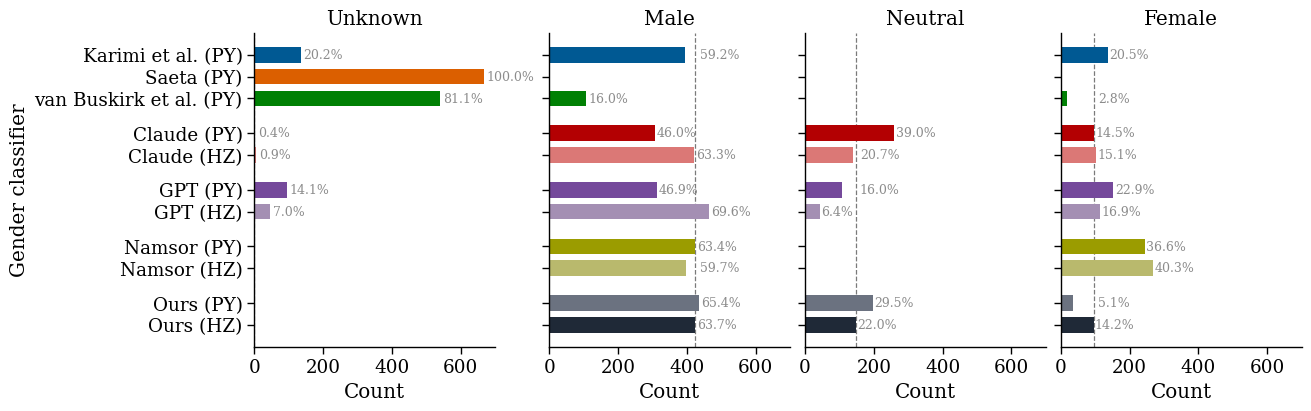

In [33]:

gap_after = [
    "py_gender_buskirk",
    "hz_gender_claude",
    "hz_gender_gpt",
    "hz_gender_namsor",
]

fn = ios.path_join(PLOT_OTHERS_COMBINED_DIR, 'aps_gender_baseline_comparison.pdf')
print(fn)

fig, axes = vis.plot_gender_facets(
    df_gender_aps_cnki,
    method_cols=APS_METHOD_ORDER,
    y_name_map=APS_METHOD_LABELS,
    y_order=APS_METHOD_ORDER,
    method_color_map=APS_METHOD_COLOR,
    reference_method="hz_gender",
    gap_after=gap_after,
    gap_size=0.6,
    col_name_map=GENDER_MAP,
    col_order=GENDER_LABEL_ORDER,
    figsize=(13, 4),
    show_annotations=True,
    fn=fn,
)

vis.plt.show()
vis.plt.close()


Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)



Cohen's Kappa matrix (chance-corrected agreement):


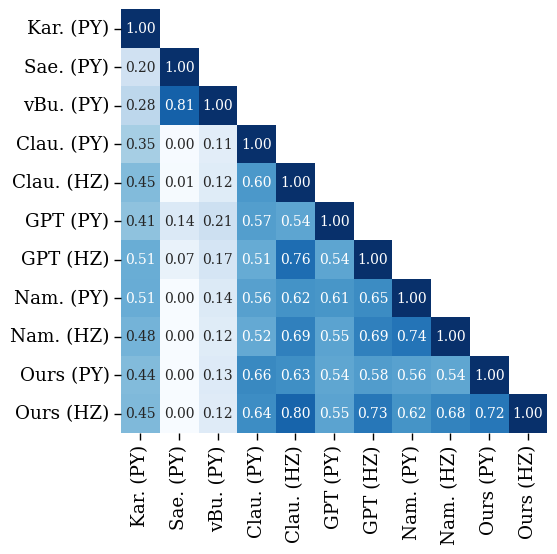

../../results/v3//gender/predictions_others/plots/aps_gender_pairwise_agreement.pdf


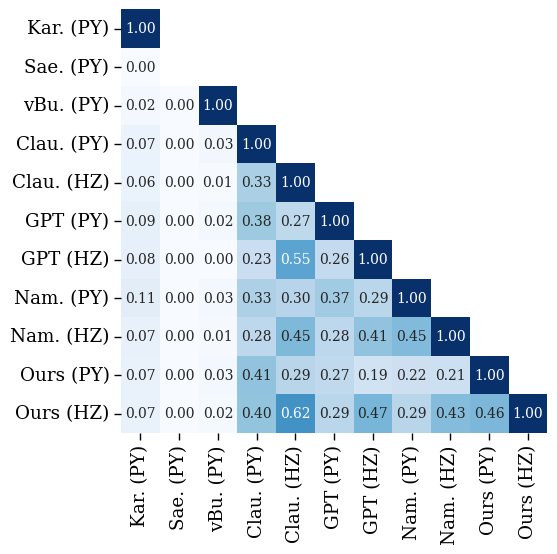

../../results/v3//gender/predictions_others/plots/aps_gender_pairwise_kappa.pdf


In [34]:

# 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
agreement_gt_ch = categorical.pairwise_agreement(df_gender_aps_cnki, APS_METHOD_ORDER)
print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
# display(agreement_gt_ch.round(2))

# 2) Cohen's Kappa — agreement corrected for chance
kappa_gt_ch = categorical.pairwise_kappa(df_gender_aps_cnki, APS_METHOD_ORDER)
print("\nCohen's Kappa matrix (chance-corrected agreement):")
# display(kappa_gt_ch.round(2))

for kind, arr in {'agreement':agreement_gt_ch,'kappa':kappa_gt_ch}.items():
    arr = arr.to_numpy()
    arr[numeric.np.triu_indices(arr.shape[0], k=1)] = numeric.np.nan

    fn = ios.path_join(PLOT_OTHERS_COMBINED_DIR, f'aps_gender_pairwise_{kind}.pdf')

    vis.plot_confusion_matrix(arr, [APS_METHOD_LABELS_SHORT[m] for m in APS_METHOD_ORDER], 
                            title=None,
                            xlabel=None,
                            ylabel=None,
                            cbar=False,
                            annot_kws={'fontsize': 10},
                            cmap='Blues', figsize=(5.5, 5.5),
                            fn=fn,
                            )
    print(fn)